# **PRUEBA EVALUACIÓN CURSO 2025-2026**

#### Instalar librerías necesarias

In [1]:
!pip install pandas openpyxl seaborn matplotlib scipy numpy statsmodels

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.2 -> 26.0
[notice] To update, run: python.exe -m pip install --upgrade pip


#### Importar librerías necesarias

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import shapiro
from statsmodels.stats.weightstats import CompareMeans, DescrStatsW
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

#### Cargar el archivo HIPERTENSION.xlsx y visualizarlo

In [3]:
df = pd.read_excel('HIPERTENSION.xlsx')

In [4]:
df

,Grupo,Edad,Presion sistólica antes,Presión sistólica después,Colesterol total
0,1,30,126,118,191
1,1,25,114,110,181
2,1,27,110,110,175
3,1,34,108,105,173
4,1,35,131,132,200
...,...,...,...,...,...
95,2,54,117,100,194
96,2,50,148,141,239
97,2,54,121,115,196
98,2,52,154,155,270


## **ENUNCIADO**

Una de las enfermedades que más preocupa a las autoridades sanitarias es la hipertensión. La hipertensión arterial afecta más del 30% de la población adulta mundial y es el principal factor de riesgo de padecer enfermedades cardiovasculares. Por ello, la lucha contra esta enfermedad es objetivo de los sistemas sanitarios de todo el mundo.
En un laboratorio europeo se está trabajando en un medicamento innovador con cierta composición de etanol para reducir la presión arterial alta
(sistólica). El medicamento se suministra a 100 pacientes de diferentes edades por vía oral en forma de comprimido. Para obtener mejores
conclusiones en el estudio, se divide a las 100 personas en dos grupos, grupo 1 (pacientes con edad igual o inferior a 35 años) y grupo 2 (pacientes con edad superior a 35 años). En la hoja de cálculo Excel llamada "HIPERTENSIÓN" aparecen los datos de las 100 personas que se han empleado en el estudio.
En la primera columna aparece la edad del paciente, en la segunda columna aparece la presión sistólica antes de la ingestión del medicamento y en la tercera columna aparece indicado el valor de la presión sistólica 60 minutos después de la toma del medicamento. Los 40 primeros datos corresponden a pacientes del primer grupo y los 60 restantes a pacientes del segundo grupo.
También se incluye una última columna donde figura el valor del colesterol total del paciente.
A partir de los datos que aparecen en la hoja de cálculo, se pide contestar a las siguientes cuestiones:

### **EJERCICIO 1**

a) Obtener, usando algún programa estadístico, las medidas de centralización y dispersión para cada uno de los dos grupos de control de
la variable (grupo 1 y grupo 2) que mide la presión sistólica antes de la toma del medicamento e indica si la media en cada uno de estos grupos
puede considerarse representativa a partir de los datos obtenidos.

In [5]:
resumen = df.groupby('Grupo')['Presion sistólica antes'].agg(['mean', 'std', 'median'])
resumen['Coeficiente de Variación %'] = (resumen['std'] / resumen['mean']) * 100
print(resumen)

print('\nComo ambos coeficientes de variación son menores al 30%, las medias sí que son representativas.')

             mean        std  median  Coeficiente de Variación %
Grupo                                                           
1      123.425000   9.026705   124.5                    7.313515
2      127.483333  13.888773   126.0                   10.894580

Como ambos coeficientes de variación son menores al 30%, las medias sí que son representativas.


b) Estudiar la simetría y la curtosis del nivel de presión sistólica en los pacientes del segundo grupo para cada una de las mediciones de la
hipertensión que aparecen en la tabla interpretando los valores obtenidos.

In [6]:
cols = ['Presion sistólica antes', 'Presión sistólica después']
print(df[df['Grupo'] == 2][cols].agg(['skew', 'kurt']))

print('\nPresión sistólica antes: \n  Simetría = -0.13 (Simétrica) \n  Curtosis = -0.6 (Aplanada)')
print('\nPresión sistólica después: \n  Simetría = -0.19 (Simétrica) \n  Curtosis = 0.37 (Normal)')

      Presion sistólica antes  Presión sistólica después
skew                -0.136599                  -0.193776
kurt                -0.602056                   0.369188

Presión sistólica antes: 
  Simetría = -0.13 (Simétrica) 
  Curtosis = -0.6 (Aplanada)

Presión sistólica después: 
  Simetría = -0.19 (Simétrica) 
  Curtosis = 0.37 (Normal)


c) Indicar para cada una de las variables relacionadas con la medición de la presión sistólica que aparecen en el fichero el valor de los cuartiles y su significado y obtener el box-plot ( diagrama de cajas) correspondiente. Estudiar la presencia de valores atípicos.

       Presion sistólica antes  Presión sistólica después
count               100.000000                 100.000000
mean                125.860000                 122.030000
std                  12.290277                  14.754869
min                  96.000000                  77.000000
25%                 118.000000                 115.000000
50%                 125.000000                 120.000000
75%                 135.000000                 131.250000
max                 154.000000                 161.000000

Q1 (25%): El 25% de los pacientes tiene una presión igual o inferior a los valores de 118 antes y 115 después.
Q2 (Mediana): Es el valor central. El 50% de los pacientes tiene menos de 125 (antes) y 120 (después). La mediana baja tras el tratamiento, lo cual es buena señal.
Q3 (75%): El 75% de los pacientes está por debajo de este valor. Solo el 25% de los pacientes "más hipertensos" supera los 135 (antes) o 131.25 (después).



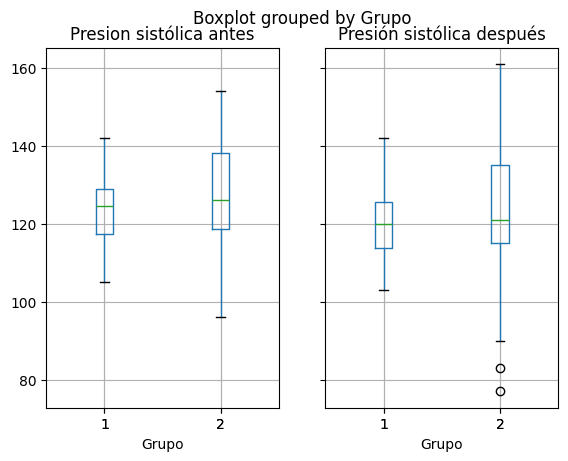

Mientras que la presión antes del tratamiento es una variable homogénea sin extremos, la variable después muestra 5 valores atípicos.
Esto sugiere que el medicamento tiene efectos distintos: en algunos pacientes no funciona (siguen muy altos) y en otros funciona demasiado y les baja la tensión excesivamente,generando outliers por la izquierda.


In [7]:
print(df[cols].describe())

print('\nQ1 (25%): El 25% de los pacientes tiene una presión igual o inferior a los valores de 118 antes y 115 después.' \
'\nQ2 (Mediana): Es el valor central. El 50% de los pacientes tiene menos de 125 (antes) y 120 (después). La mediana baja tras el tratamiento, lo cual es buena señal.' \
'\nQ3 (75%): El 75% de los pacientes está por debajo de este valor. Solo el 25% de los pacientes "más hipertensos" supera los 135 (antes) o 131.25 (después).\n')

df.boxplot(column=cols, by='Grupo')
plt.show()

print('Mientras que la presión antes del tratamiento es una variable homogénea sin extremos, la variable después muestra 5 valores atípicos.' \
'\nEsto sugiere que el medicamento tiene efectos distintos: en algunos pacientes no funciona (siguen muy altos) y en otros funciona demasiado y les baja la tensión excesivamente,' \
'generando outliers por la izquierda.')

d) Estudiar la normalidad de los datos de las variables relacionadas con la medición de la presión sistólica.


In [8]:
print(shapiro(df['Presion sistólica antes']))
print(shapiro(df['Presión sistólica después']))

print('\nPresión sistólica antes: P-value = 0.81 (> 0.05) -> Es normal' \
'\nPresión sistólica después: P-value = 0.10 (> 0.05) -> Es normal')

ShapiroResult(statistic=np.float64(0.9919231354802636), pvalue=np.float64(0.8156294109699813))
ShapiroResult(statistic=np.float64(0.9788826299968818), pvalue=np.float64(0.10874561600201343))

Presión sistólica antes: P-value = 0.81 (> 0.05) -> Es normal
Presión sistólica después: P-value = 0.10 (> 0.05) -> Es normal


### **EJERCICIO 2**
Con los datos del fichero anterior, se quiere estudiar la relación existente entre la presión sistólica después de la toma del medicamento y el colesterol total del paciente en los pacientes jóvenes ( grupo 1).

In [9]:
g1 = df[df['Grupo'] == 1]
X = g1['Colesterol total']
Y = g1['Presión sistólica después']

a) Estudiar la relación lineal entre estas dos variables.

Coeficiente de Correlación (Pearson): 0.7485
Existe una correlación positiva fuerte. A mayor colesterol, mayor presión sistólica final.


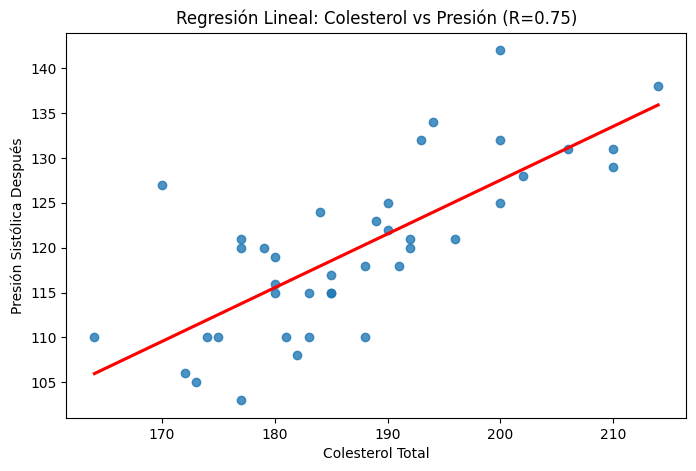

In [10]:
r = X.corr(Y)

print(f'Coeficiente de Correlación (Pearson): {r:.4f}')
print('Existe una correlación positiva fuerte. A mayor colesterol, mayor presión sistólica final.')

plt.figure(figsize=(8, 5))
sns.regplot(x=X, y=Y, ci=None, line_kws={"color": "red"})
plt.title(f'Regresión Lineal: Colesterol vs Presión (R={r:.2f})')
plt.xlabel('Colesterol Total')
plt.ylabel('Presión Sistólica Después')
plt.show()

b) Obtener un modelo lineal que explica la presión sistólica del paciente joven a los 60 minutos de ingerir el medicamento en función de su colesterol total y realizar la estimación para un paciente del grupo 1 ( joven) cuyo colesterol total es 105 mg/Dl.

In [11]:
slope, intercept, r_value, p_value, std_err = stats.linregress(X, Y)
x_nuevo = 105

print(f'Modelo lineal -> Y (presión sistólica después) = a (punto de corte con el eje vertical) + b (inclinación de la recta) * X (colesterol) \
    \nPresión = {intercept:.2f} + {slope:.4f} * {x_nuevo}')

print(f'\nPredicción para un colesterol de 105 mg/Dl: {intercept + slope * x_nuevo:.2f} mmHg')

Modelo lineal -> Y (presión sistólica después) = a (punto de corte con el eje vertical) + b (inclinación de la recta) * X (colesterol)     
Presión = 7.78 + 0.5987 * 105

Predicción para un colesterol de 105 mg/Dl: 70.64 mmHg


c) ¿Qué tanto por ciento de la presión sistólica del paciente joven a los 60 minutos de ingerir el medicamento no queda explicado por el anterior modelo? ¿Cómo podrías mejorar el modelo?

In [12]:
r_squared = r_value**2
no_explicado = (1 - r_squared) * 100

print(f'Porcentaje no explicado: {no_explicado:.2f}%')

print('Para mejorar el modelo podríamos aumentar el tamaño de la muestra o ' \
    'incluir más variables como peso, dieta, ejercicio, antecedentes familiares...')


Porcentaje no explicado: 43.98%
Para mejorar el modelo podríamos aumentar el tamaño de la muestra o incluir más variables como peso, dieta, ejercicio, antecedentes familiares...


d) Si aumentásemos el colesterol de un paciente en 5 mg/Dl ¿Qué variación experimentaría su presión sistólica después de 60 minutos de ingerir el medicamento?

In [13]:
aumento_x = 5
variacion_y = slope * aumento_x

print(f'Si el colesterol sube {aumento_x} mg/Dl, la presión sube: {variacion_y:.2f} mmHg')

Si el colesterol sube 5 mg/Dl, la presión sube: 2.99 mmHg


### **EJERCICIO 3**

a) Se quiere estudiar si se puede admitir que la presión sistólica media en el momento de la ingestión de la población adulta (grupo 2) es 130
mm de Hg. Obtener el intervalo de confianza al 95% y al 99% para el nivel medio de presión sistólica antes de la toma del medicamento en el grupo de los adultos y posteriormente contesta a la cuestión planteada con los resultados obtenidos o mediante un contraste de hipótesis.

In [14]:
g2 = df[df['Grupo'] == 2]
variable_estudio = g2['Presion sistólica antes']

media_muestral = variable_estudio.mean()
error_estandar = variable_estudio.sem()
grados_libertad = len(variable_estudio) - 1

intervalo_95_media = stats.t.interval(0.95, df=grados_libertad, loc=media_muestral, scale=error_estandar)
intervalo_99_media = stats.t.interval(0.99, df=grados_libertad, loc=media_muestral, scale=error_estandar)

valor_referencia = 130
t_stat, p_valor_test_media = stats.ttest_1samp(variable_estudio, popmean=valor_referencia)

print(f"Media muestral: {media_muestral:.2f}")
print(f"IC 95% media: {np.round(intervalo_95_media, 2)}")
print(f"IC 99% media: {np.round(intervalo_99_media, 2)}")
print(f"P-Valor (H0: mu=130): {p_valor_test_media:.4f}")

print('\nComo p-valor > 0.05 y el valor 130 está dentro de ambos intervalos, ' \
    'no rechazamos la hipótesis nula. Se puede afirmar que la presión media inicial de los adultos es de 130 mmHg.')

Media muestral: 127.48
IC 95% media: [123.9  131.07]
IC 99% media: [122.71 132.26]
P-Valor (H0: mu=130): 0.1657

Como p-valor > 0.05 y el valor 130 está dentro de ambos intervalos, no rechazamos la hipótesis nula. Se puede afirmar que la presión media inicial de los adultos es de 130 mmHg.


b) Obtener el intervalo de confianza al 95% para la diferencia de medias en la presión sistólica entre adultos y jóvenes después de la ingestión
del medicamento. ¿Se puede concluir que después de la ingesta del medicamento la presión sistólica media de la población es distinta dependiendo de la edad?

In [15]:
comparador = CompareMeans(DescrStatsW(g2['Presión sistólica después']), 
                          DescrStatsW(g1['Presión sistólica después']))
intervalo_diferencia_95 = comparador.tconfint_diff(alpha=0.05, usevar='pooled')

print(f"IC 95% de la Diferencia: {np.round(intervalo_diferencia_95, 2)}")

print('\nEl intervalo contiene el 0 por lo que no hay evidencia suficiente para afirmar que las medias son distintas. ' \
'No se puede concluir que la presión sistólica media después de la ingesta sea distinta dependiendo de la edad (p-value > 0.05).')

IC 95% de la Diferencia: [-2.41  9.51]

El intervalo contiene el 0 por lo que no hay evidencia suficiente para afirmar que las medias son distintas. No se puede concluir que la presión sistólica media después de la ingesta sea distinta dependiendo de la edad (p-value > 0.05).


c) Se quiere estudiar la proporción de la población con una presión sistólica inicial igual o superior a 130 mm de Hg (prehipertensión). A partir de la muestra del fichero (tomando todos los datos de presión sistólica antes de la toma del medicamento) obtener un intervalo de confianza al 99% de la proporción de la población con hipertensión y contrastar la hipótesis que el porcentaje de la población con presión sistólica superior o igual a 130 mm de Hg es 0,30 con nivel de significación del 5%.

In [16]:
total_n = len(df)
casos_prehipertension = (df['Presion sistólica antes'] >= 130).sum()

proporcion_muestral = casos_prehipertension / total_n

intervalo_proporcion_99 = proportion_confint(count=casos_prehipertension, 
                                             nobs=total_n, 
                                             alpha=0.01, 
                                             method='normal')

z_stat, p_valor_test_proporcion = proportions_ztest(count=casos_prehipertension, 
                                                    nobs=total_n, 
                                                    value=0.30)

print(f"Proporción muestral: {proporcion_muestral:.2f}")
print(f"IC 99% Proporción: {np.round(intervalo_proporcion_99, 3)}")
print(f"P-Valor (H0: p=0.30): {p_valor_test_proporcion:.4f}")

print('\nComo p-valor > 0.05, aceptamos la hipótesis de que el 30% de la población sufre prehipertensión, ' \
'ya que la diferencia que se observa (35% vs 30%) no es significativa.')

Proporción muestral: 0.35
IC 99% Proporción: [0.227 0.473]
P-Valor (H0: p=0.30): 0.2945

Como p-valor > 0.05, aceptamos la hipótesis de que el 30% de la población sufre prehipertensión, ya que la diferencia que se observa (35% vs 30%) no es significativa.


d) Por último, se quiere estudiar la eficacia del medicamento en la población adulta. ¿Existe variación significativa de la presión sistólica después de la toma del medicamento en la población del grupo 2? Plantea el correspondiente contraste de hipótesis considerando un nivel de significación del 5%. 
###### Ayuda: Para contestar a la pregunta has de considerar la series de datos obtenidas a partir de las diferencias entre la presión sistólica antes de la toma y la presión sistólica al cabode 60 minutos en el grupo de los adultos (contraste de muestras emparejadas).

In [17]:
t_stat, p_valor_eficacia = stats.ttest_rel(g2['Presion sistólica antes'], 
                                           g2['Presión sistólica después'])

print(f"P-Valor (Antes vs Después): {p_valor_eficacia:.6f}")

print('\nEl p-valor es muy bajo, lo que indica que sí que existe una variación significativa. ' \
'El medicamento reduce la presión arterial en el grupo de adultos eficazmente.')

P-Valor (Antes vs Después): 0.000363

El p-valor es muy bajo, lo que indica que sí que existe una variación significativa. El medicamento reduce la presión arterial en el grupo de adultos eficazmente.
